<a href="https://colab.research.google.com/github/XuningZhuang/MSSP6070/blob/main/Assignments/Assignment2_Xuning_Zhuang.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata

github_token = userdata.get('6070777')
owner = 'XuningZhuang'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

!git clone {clone_url}

Cloning into 'MSSP6070'...
remote: Enumerating objects: 195, done.
remote: Counting objects: 100% (195/195), done.
remote: Compressing objects: 100% (184/184), done.
remote: Total 195 (delta 103), reused 23 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (195/195), 8.00 MiB | 3.40 MiB/s, done.
Resolving deltas: 100% (103/103), done.
Updating files: 100% (47/47), done.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/MSSP6070/data/InternetSales.csv', encoding='latin-1')
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

/tmp/ipykernel_512/2544521234.py:5: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/MSSP6070/data/InternetSales.csv', encoding='latin-1')


In [3]:
print(df.shape)
print(df.columns.tolist())

(60398, 60)
['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'CustomerPONumber', 'OrderDate', 'DueDat

In [4]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['Year'] = df['OrderDate'].dt.year

print(df['OrderDate'].min())
print(df['OrderDate'].max())
print(df['Year'].value_counts().sort_index())

2010-12-29 00:00:00
2014-01-28 00:00:00
Year
2010       14
2011     2216
2012     3397
2013    52801
2014     1970
Name: count, dtype: int64


In [5]:
#A
total_overall_sales = df['SalesAmount'].sum()

print('Total Internet Sales:', total_overall_sales)

Total Internet Sales: 29358677.220699992


In [6]:
country_stats = df.groupby('EnglishCountryRegionName')['SalesAmount'].agg(['count', 'sum', 'mean', 'median', 'std'])

country_stats = country_stats.sort_values('sum', ascending=False)

print(country_stats)

                          count           sum        mean  median          std
EnglishCountryRegionName                                                      
United States             21344  9.389790e+06  439.926420   29.99   893.534310
Australia                 13345  9.061001e+06  678.980936   34.99  1074.124424
United Kingdom             6906  3.391712e+06  491.125429   29.99   900.427387
Germany                    5625  2.894312e+06  514.544416   32.60   918.170934
France                     5558  2.644018e+06  475.713874   29.99   887.339536
Canada                     7620  1.977845e+06  259.559693   24.49   722.628771


In [7]:
sales_by_country_year = df.groupby(['Year', 'EnglishCountryRegionName'])['SalesAmount'].sum().unstack(fill_value=0)

sales_by_country_year['Year Total'] = sales_by_country_year.sum(axis=1)

country_total = sales_by_country_year.drop(columns='Year Total').sum()

print(sales_by_country_year)
print()
print('Country totals:')
print(country_total)
print()
print('Overall total:')
print(df['SalesAmount'].sum())

EnglishCountryRegionName     Australia        Canada        France  \
Year                                                                 
2010                      2.090978e+04  3.578270e+03  3.399990e+03   
2011                      2.563732e+06  5.715718e+05  4.108453e+05   
2012                      2.128407e+06  3.076045e+05  6.480655e+05   
2013                      4.339443e+06  1.085633e+06  1.578512e+06   
2014                      8.507720e+03  9.457620e+03  3.195060e+03   

EnglishCountryRegionName       Germany  United Kingdom  United States  \
Year                                                                    
2010                      0.000000e+00    6.990982e+02   1.483390e+04   
2011                      5.205002e+05    5.505912e+05   2.458285e+06   
2012                      6.086580e+05    7.127010e+05   1.437049e+06   
2013                      1.761876e+06    2.124007e+06   5.462079e+06   
2014                      3.277830e+03    3.713640e+03   1.754285e+04  

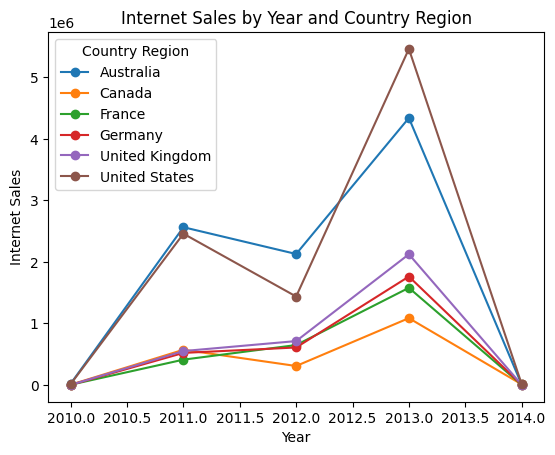

In [8]:
sales_by_country_year.drop(columns='Year Total').plot(kind='line', marker='o')

plt.xlabel('Year')
plt.ylabel('Internet Sales')
plt.title('Internet Sales by Year and Country Region')
plt.legend(title='Country Region')
plt.show()

In [9]:
#B
income_stats = df.groupby(['EnglishCountryRegionName', 'Gender'])['YearlyIncome'].agg(['count', 'mean', 'min', 'max', 'std'])

print(income_stats)

                                 count          mean    min     max  \
EnglishCountryRegionName Gender                                       
Australia                F        6685  67060.583396  10000  160000   
                         M        6660  65412.912913  10000  170000   
Canada                   F        3648  58651.315789  10000  170000   
                         M        3972  61460.221551  10000  170000   
France                   F        2781  39367.134124  10000  110000   
                         M        2777  39805.545553  10000  110000   
Germany                  F        2820  48287.234043  10000  130000   
                         M        2805  46730.837790  10000  130000   
United Kingdom           F        3401  56518.670979  10000  170000   
                         M        3505  55771.754636  10000  170000   
United States            F       10682  64766.897585  10000  170000   
                         M       10662  65450.196961  10000  170000   

     

In [10]:
income_mean = df.groupby(['EnglishCountryRegionName', 'Gender'])['YearlyIncome'].mean().unstack()

print(income_mean)

Gender                               F             M
EnglishCountryRegionName                            
Australia                 67060.583396  65412.912913
Canada                    58651.315789  61460.221551
France                    39367.134124  39805.545553
Germany                   48287.234043  46730.837790
United Kingdom            56518.670979  55771.754636
United States             64766.897585  65450.196961


In [11]:
income_diff = income_mean['M'] - income_mean['F']

print("Mean Yearly Income Difference (M - F) by Country:")
print(income_diff.round(2).apply(lambda x: f"{x:,.3f}"))

Mean Yearly Income Difference (M - F) by Country:
EnglishCountryRegionName
Australia         -1,647.670
Canada             2,808.910
France               438.410
Germany           -1,556.400
United Kingdom      -746.920
United States        683.300
dtype: object


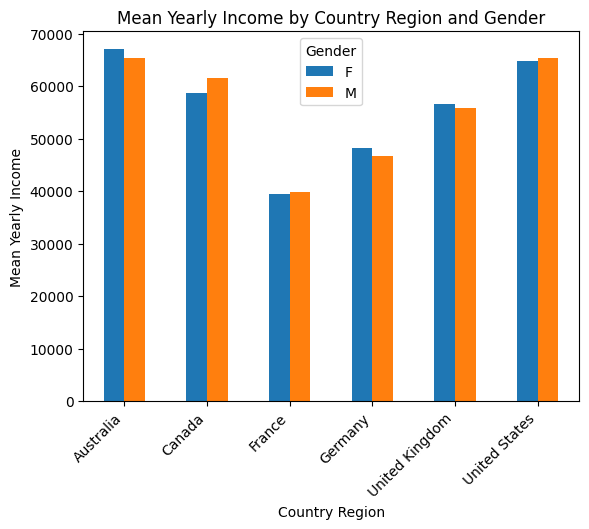

In [12]:
income_mean.plot(kind='bar')

plt.xlabel('Country Region')
plt.ylabel('Mean Yearly Income')
plt.title('Mean Yearly Income by Country Region and Gender')
plt.xticks(rotation=45, ha='right')
plt.show()

In [13]:
#C
df['ProductCategory'] = 'Accessories'

df.loc[ df['EnglishProductName'].str.contains('Mountain-|Road-|Touring-', na=False, regex=True),
    'ProductCategory'] = 'Bikes'

df.loc[df['EnglishProductName'].str.contains('Tire|Tube|Fender Set|Bottle Cage', na=False, regex=True),
    'ProductCategory'] = 'Components'

df.loc[df['EnglishProductName'].str.contains('Jersey|Vest|Gloves|Socks|Shorts|Helmet|Cap', na=False, regex=True),
    'ProductCategory'] = 'Clothing'

print(df['ProductCategory'].value_counts())

ProductCategory
Components     19999
Clothing       15541
Bikes          15205
Accessories     9653
Name: count, dtype: int64


In [14]:
category_stats = df.groupby('ProductCategory')['SalesAmount'].agg(['count', 'sum', 'mean', 'median', 'std']).sort_values('sum', ascending=False)

category_stats['% of Total Sales'] = (category_stats['sum'] / df['SalesAmount'].sum() * 100)

print(category_stats)

                 count           sum         mean     median         std  \
ProductCategory                                                            
Bikes            15205  2.831814e+07  1862.423193  2071.4196  944.116065   
Clothing         15541  5.651082e+05    36.362410    34.9900   17.325393   
Components       19999  3.204621e+05    16.023908     9.9900   11.029458   
Accessories       9653  1.549622e+05    16.053270     4.9900   33.646395   

                 % of Total Sales  
ProductCategory                    
Bikes                   96.455792  
Clothing                 1.924842  
Components               1.091541  
Accessories              0.527824  


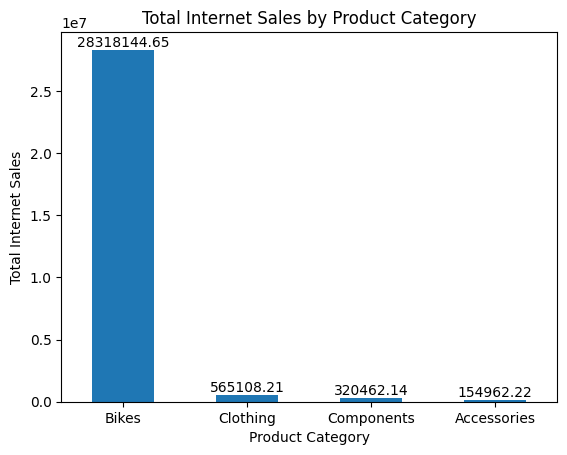

In [15]:
category_stats['sum'].plot(kind='bar')

plt.xlabel('Product Category')
plt.ylabel('Total Internet Sales')
plt.title('Total Internet Sales by Product Category')
plt.xticks(rotation=0)
plt.gca().bar_label(plt.gca().containers[0], fmt='%.2f')

plt.show()

In [16]:
category_price = df.groupby('ProductCategory')['UnitPrice'].mean().sort_values(ascending=False)

print(category_price)

ProductCategory
Bikes          1862.423193
Clothing         36.362410
Accessories      16.053270
Components       16.023908
Name: UnitPrice, dtype: float64


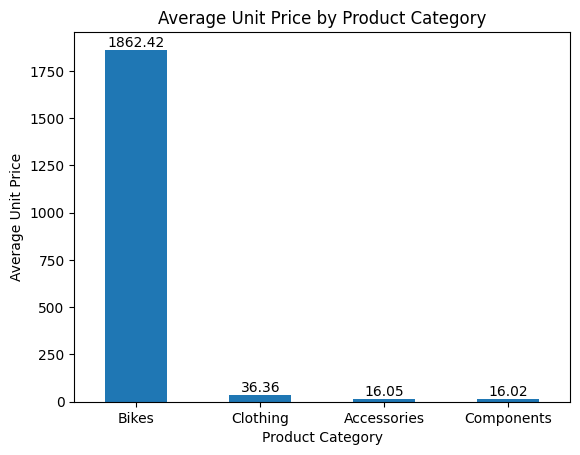

In [17]:
category_price.plot(kind='bar')

plt.xlabel('Product Category')
plt.ylabel('Average Unit Price')
plt.title('Average Unit Price by Product Category')
plt.xticks(rotation=0)
plt.gca().bar_label(plt.gca().containers[0], fmt='%.2f')

plt.show()

In [18]:
top_category = category_stats.index[0]

top_category_price = df.loc[df['ProductCategory'] == top_category,'UnitPrice'].mean()

print('Highest-selling category:', top_category)
print('Average UnitPrice:', top_category_price)

Highest-selling category: Bikes
Average UnitPrice: 1862.4231930746462


In [19]:
#D
home_stats = df.groupby('HouseOwnerFlag')['SalesAmount'].agg(['count', 'sum', 'mean', 'median', 'std'])

print(home_stats)

                count           sum        mean  median         std
HouseOwnerFlag                                                     
0               18699  8.973327e+06  479.882744   29.99  924.841795
1               41699  2.038535e+07  488.869033   32.60  930.118780


In [20]:
home_difference = (home_stats.loc[1, 'mean']-home_stats.loc[0, 'mean'])

print('Difference in mean SalesAmount:', home_difference)

Difference in mean SalesAmount: 8.986289021030416


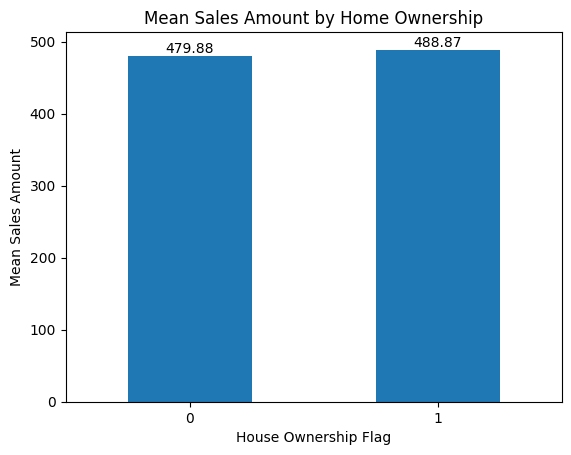

In [21]:
home_stats['mean'].plot(kind='bar')

plt.xlabel('House Ownership Flag')
plt.ylabel('Mean Sales Amount')
plt.title('Mean Sales Amount by Home Ownership')
plt.xticks(rotation=0)
plt.gca().bar_label(plt.gca().containers[0], fmt='%.2f')

plt.show()


In [22]:
#E
product_stats = df.groupby('EnglishProductName')['SalesAmount'].agg(['count', 'sum', 'mean', 'median', 'std']).sort_values('sum', ascending=False)

print(product_stats.head(10))

                         count           sum         mean   median         std
EnglishProductName                                                            
Mountain-200 Black, 46     620  1.373470e+06  2215.273465  2294.99  115.188180
Mountain-200 Black, 42     614  1.363142e+06  2220.101129  2294.99  113.256820
Mountain-200 Silver, 38    596  1.339463e+06  2247.420789  2319.99  113.109387
Mountain-200 Silver, 46    580  1.301100e+06  2243.276032  2319.99  114.919793
Mountain-200 Black, 38     582  1.294866e+06  2224.855913  2294.99  111.120758
Mountain-200 Silver, 42    560  1.257435e+06  2245.418880  2319.99  114.011108
Road-150 Red, 48           337  1.205877e+06  3578.270000  3578.27    0.000000
Road-150 Red, 62           336  1.202299e+06  3578.270000  3578.27    0.000000
Road-150 Red, 52           302  1.080638e+06  3578.270000  3578.27    0.000000
Road-150 Red, 56           295  1.055590e+06  3578.270000  3578.27    0.000000


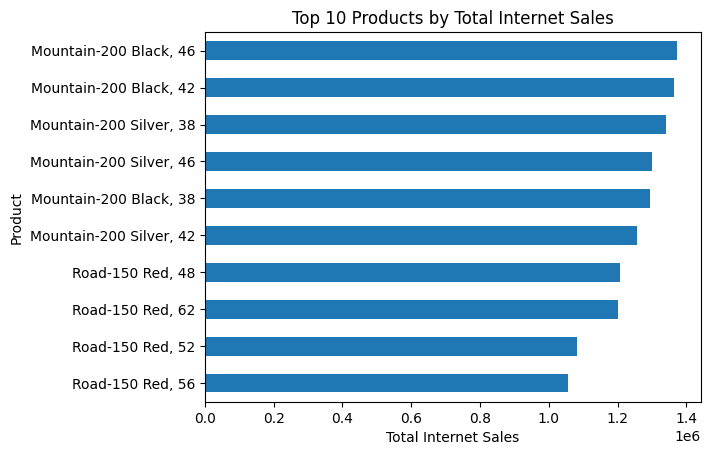

In [23]:
product_stats.head(10)['sum'].sort_values().plot(kind='barh')

plt.xlabel('Total Internet Sales')
plt.ylabel('Product')
plt.title('Top 10 Products by Total Internet Sales')
plt.show()